In [1]:
import numpy as np
import pandas as pd


In [5]:
data_airbnb = pd.read_csv("listings.csv.gz")

In [7]:
print(data_airbnb.head())

      id                         listing_url       scrape_id last_scraped  \
0  28871  https://www.airbnb.com/rooms/28871  20260615212022   2026-06-16   
1  29051  https://www.airbnb.com/rooms/29051  20260615212022   2026-06-16   
2  44129  https://www.airbnb.com/rooms/44129  20260615212022   2026-06-24   
3  44391  https://www.airbnb.com/rooms/44391  20260615212022   2026-06-24   
4  48373  https://www.airbnb.com/rooms/48373  20260615212022   2026-06-24   

            source                                             name  \
0  previous scrape                          Comfortable double room   
1  previous scrape                 Comfortable single / double room   
2  previous scrape                    Luxury design with canal view   
3  previous scrape  Quiet 2-bedroom Amsterdam city centre apartment   
4  previous scrape              Cozy family home in Amsterdam South   

                                         description  neighborhood_overview  \
0          Basic bedroom in the

In [10]:
df.shape

(10369, 90)

The data set includes 10369 observations each observation represents one listing on airbnb. The data set also includes 90 coloumns each represeting a different variable. 

In [11]:
for i, col in enumerate(df.columns, 1):
    print(i, col)

1 id
2 listing_url
3 scrape_id
4 last_scraped
5 source
6 name
7 description
8 neighborhood_overview
9 picture_url
10 host_id
11 host_url
12 host_profile_id
13 host_profile_url
14 host_name
15 host_since
16 hosts_time_as_user_years
17 hosts_time_as_user_months
18 hosts_time_as_host_years
19 hosts_time_as_host_months
20 host_location
21 host_about
22 host_response_time
23 host_response_rate
24 host_acceptance_rate
25 host_is_superhost
26 host_thumbnail_url
27 host_picture_url
28 host_neighbourhood
29 host_listings_count
30 host_total_listings_count
31 host_verifications
32 host_has_profile_pic
33 host_identity_verified
34 neighbourhood
35 neighbourhood_cleansed
36 neighbourhood_group_cleansed
37 latitude
38 longitude
39 property_type
40 room_type
41 accommodates
42 bathrooms
43 bathrooms_text
44 bedrooms
45 beds
46 amenities
47 price
48 price_quote_checkin_date
49 price_quote_checkout_date
50 price_quote_total_price
51 price_quote_price_per_night
52 price_quote_raw
53 minimum_nights
54 m

for the purpose of convenience let's establish these 90 varaibles into distinct categories:
1. listing identification (1-10)
2. host charactarestics (11-33)
3. neighbourhood info (34-38), this catgory is important for our specefied project proposal
4. property charactarestics (39-46), this category also might prove important 
5. price information (47-52), this is the most important group because price is our target variable 
6. booking restrictions and stay charactarestics (53-61)
7. Availability, reviews and estimated activity (62-83)
8. other info (84-90)

In [15]:
data_airbnb.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object

In [14]:
data_airbnb[['price', 'room_type', 'property_type', 'accommodates',
    'bathrooms', 'bedrooms', 'beds', 'minimum_nights',
    'number_of_reviews', 'review_scores_rating']].describe(include='all')

,price,room_type,property_type,accommodates,bathrooms,bedrooms,beds,minimum_nights,number_of_reviews,review_scores_rating
count,6377,10369,10369,10369.000000,5413.000000,9219.000000,5717.000000,10366.000000,10369.000000,9346.000000
unique,2709,4,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,$314.00,Entire home/apt,Entire rental unit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,44,8489,4451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2.941364,1.248014,1.634234,1.903096,3.591646,51.703539,4.850425
std,NaN,NaN,NaN,1.278998,0.529313,0.890917,1.533525,14.112109,143.771159,0.243524
min,NaN,NaN,NaN,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,1.000000
25%,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,1.000000,3.000000,4.800000
50%,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,2.000000,10.000000,4.920000
75%,NaN,NaN,NaN,4.000000,1.500000,2.000000,2.000000,3.000000,32.000000,5.000000


In [ ]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing) 

# the above code allows us to ispect which varaibles have non zero missing values ordered from most to least 

host_response_time              10369
neighbourhood                   10369
host_verifications              10369
host_total_listings_count       10369
neighbourhood_group_cleansed    10369
host_neighbourhood              10369
host_thumbnail_url              10369
host_acceptance_rate            10369
host_response_rate              10369
calendar_updated                10369
neighborhood_overview           10369
host_since                      10369
instant_bookable                10369
host_about                       4959
bathrooms                        4956
beds                             4652
price                            3992
price_quote_price_per_night      3992
estimated_revenue_l365d          3992
price_quote_total_price          3992
price_quote_raw                  3861
price_quote_checkin_date         3861
price_quote_checkout_date        3861
host_location                    1372
bedrooms                         1150
review_scores_cleanliness        1024
first_review

Important missing varaibles:

1. bathrooms                        4956
2. beds                             4652
3. price                            3992
4. price_quote_price_per_night      3992
5. estimated_revenue_l365d          3992
6. price_quote_total_price          3992
7. price_quote_raw                  3861
8. bedrooms                         1150



In [34]:
data_airbnb[data_airbnb['price'].isna()][
    ['id','has_availability','availability_365','price','price_quote_price_per_night']
].head(20)


,id,has_availability,availability_365,price,price_quote_price_per_night
1,29051,t,2,NaN,NaN
3,44391,t,0,NaN,NaN
4,48373,t,0,NaN,NaN
8,53921,t,0,NaN,NaN
9,55868,t,0,NaN,NaN
11,80635,t,0,NaN,NaN
15,155548,t,0,NaN,NaN
17,168769,t,0,NaN,NaN
18,171054,t,0,NaN,NaN
22,190943,t,0,NaN,NaN


In [36]:
data_airbnb[data_airbnb['price'].isna()]['availability_365'].mean()

np.float64(6.424599198396794)

<Axes: ylabel='Frequency'>

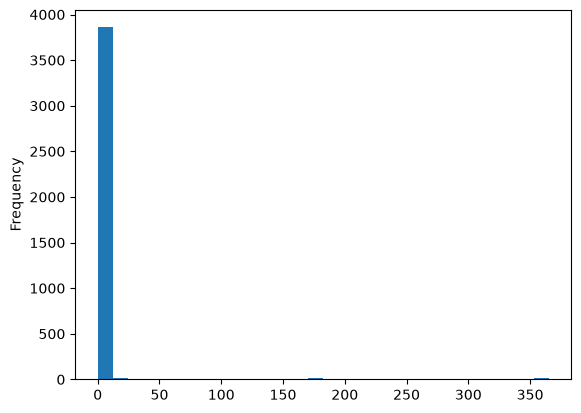

In [42]:
import matplotlib.pyplot as plt

data_airbnb[data_airbnb['price'].isna()]['availability_365'].plot.hist(bins=30)



this graph tell us something important, and its that the overwhelming majority of listings with a missing price have an availablity that gravitates around the number zero which tells us the reason why the data is missing in the first place

In [43]:
df['id'].duplicated().sum()

np.int64(0)

No duplicate IDs which is a good sign 

In [45]:
data_airbnb['minimum_nights'].describe()

count    10366.000000
mean         3.591646
std         14.112109
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        800.000000
Name: minimum_nights, dtype: float64

a potential issue we might have to investigate is the max of 800

<Axes: ylabel='Frequency'>

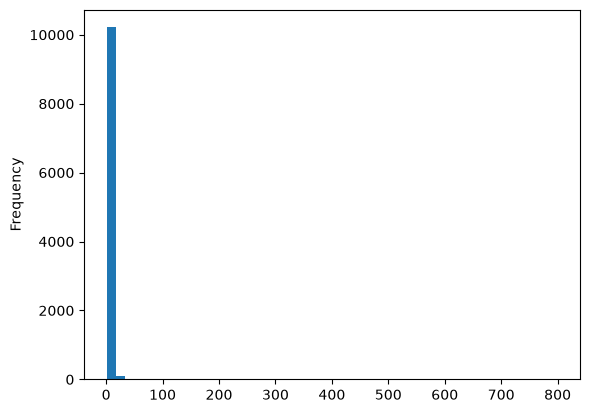

In [48]:
data_airbnb['minimum_nights'].plot.hist(bins=50)

In [49]:
data_airbnb['minimum_nights'].value_counts().sort_index(ascending=False).head(20)

minimum_nights
800.0     1
365.0     3
364.0     2
363.0     2
300.0     1
299.0     1
180.0     1
100.0     1
99.0      1
90.0     23
80.0      1
75.0      1
60.0      1
55.0      1
50.0      1
48.0      1
45.0      2
40.0      1
31.0      3
30.0     30
Name: count, dtype: int64

In [53]:
price_numeric = (
    df['price']
    .str.replace('$', '')
    .str.replace(',', '')
    .astype(float)
)
price_numeric.describe()

count     6377.000000
mean       346.621932
std        327.297968
min         14.700000
25%        206.670000
50%        291.000000
75%        411.000000
max      11412.000000
Name: price, dtype: float64

<Axes: ylabel='Frequency'>

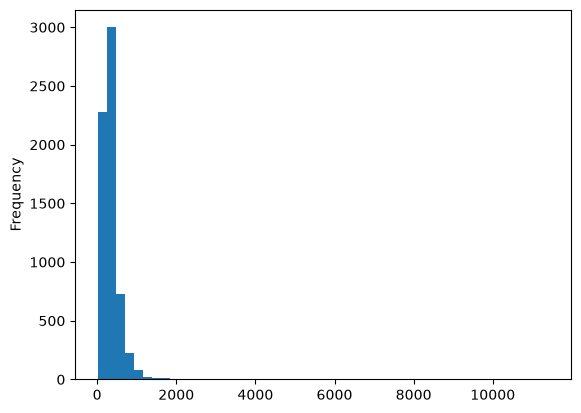

In [54]:
price_numeric.plot.hist(bins=50)

skewed right

In [57]:
price_numeric.sort_values(ascending=False).head(20)

9551     11412.00
373      11411.80
4364      7200.00
4499      7200.00
3491      5706.00
6267      3382.60
10292     3025.00
10310     2700.00
1502      2477.00
6350      2354.00
10081     2304.40
9300      2282.50
4957      2277.00
384       2029.71
9699      1912.00
8964      1887.00
2598      1854.50
4504      1854.50
1920      1826.00
9696      1797.35
Name: price, dtype: float64

In [60]:
df.loc[price_numeric.nlargest(20).index,
       ['price','host_id', 'property_type', 'room_type',
        'accommodates','minimum_nights', 'bedrooms', 'bathrooms',
        'beds', 'neighbourhood_cleansed', 'listing_url']]

,price,host_id,property_type,room_type,accommodates,minimum_nights,bedrooms,bathrooms,beds,neighbourhood_cleansed,listing_url
9551,"$11,412.00",182912442,Entire home,Entire home/apt,4,1.0,2.0,1.0,2.0,De Pijp - Rivierenbuurt,https://www.airbnb.com/rooms/1548025772403046607
373,"$11,411.80",10428722,Entire rental unit,Entire home/apt,2,5.0,1.0,1.0,1.0,Centrum-West,https://www.airbnb.com/rooms/2474754
4364,"$7,200.00",18081564,Boat,Entire home/apt,16,1.0,7.0,2.0,22.0,Oud-Noord,https://www.airbnb.com/rooms/612289973482163299
4499,"$7,200.00",18081564,Boat,Entire home/apt,16,1.0,17.0,17.0,30.0,Oud-Noord,https://www.airbnb.com/rooms/643315499225242586
3491,"$5,706.00",264906709,Entire rental unit,Entire home/apt,2,5.0,1.0,1.0,2.0,Zuid,https://www.airbnb.com/rooms/42910448
6267,"$3,382.60",534378749,Entire home,Entire home/apt,8,3.0,4.0,3.5,4.0,Centrum-West,https://www.airbnb.com/rooms/968203403339639631
10292,"$3,025.00",718508838,Casa particular,Entire home/apt,2,1.0,1.0,1.0,1.0,Centrum-West,https://www.airbnb.com/rooms/1693616534399481978
10310,"$2,700.00",691780400,Entire home,Entire home/apt,8,1.0,4.0,4.5,5.0,Centrum-West,https://www.airbnb.com/rooms/1698438915127575870
1502,"$2,477.00",1791317,Houseboat,Entire home/apt,4,1.0,3.0,2.0,6.0,Centrum-Oost,https://www.airbnb.com/rooms/15304003
6350,"$2,354.00",538035047,Entire loft,Entire home/apt,4,1.0,3.0,NaN,3.0,Centrum-West,https://www.airbnb.com/rooms/984625805593041593
